# 02: Fold-local ön işleme, MANUEL + OTOMATİK arama ve Nested CV
Akış: Development (%80) → **Outer StratifiedKFold(3)** → her outer-train içinde **Inner StratifiedKFold(3)** ile
6 manuel (M1-M6) ve 6 otomatik (R1-R6) aday ayrı ayrı değerlendirilir → her yöntemin seçtiği aday outer-train'de yeniden
eğitilir → outer evaluation'da **bir kez** ölçülür. Ardından tam development üzerinde iç CV ile nihai seçim yapılır,
nihai model 3 seed ile eğitilir ve **etiketsiz** test tahminleri `results/test_predictions_locked.csv` dosyasına kilitlenir.

İç döngüde üçlü ayrım: inner-train → (%85 **fit** alt kümesi: ön işleme fit + ağırlık güncelleme | %15 **early-stop monitor**:
BCE ile early stopping + ReduceLROnPlateau) ; inner validation katı: yalnızca AP ile aday karşılaştırma.

In [1]:
# --- Ortam kurulumu (Colab'da repo klonlanır; yerelde repo kökünden çalıştırın) ---
import os, sys, platform
REPO_URL = "https://github.com/ibrahimalpsoy/ysa-midterm-bank-mlp.git"
if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists("ysa-midterm-bank-mlp"):
        os.system(f"git clone {REPO_URL}")
    os.chdir("ysa-midterm-bank-mlp")
    os.system("pip install -q -r requirements.txt")
sys.path.insert(0, os.path.abspath("."))

import json, warnings
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from src import config as C
C.ensure_dirs(); C.set_global_seeds()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9})
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("BASE_SEED =", C.BASE_SEED, "| türetilmiş seedler:", C.SEEDS)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5
BASE_SEED = 31066 | türetilmiş seedler: {'python': 31066, 'numpy': 31067, 'torch': 31068, 'split': 31069, 'outer_cv': 31070, 'inner_cv': 31071, 'random_search': 31072, 'early_stop_split': 31073, 'bootstrap': 31074}


In [2]:
import time, platform, joblib, torch
from src import data as D, search as S
from src.model import MLPPipeline, count_params
from src.metrics import METRIC_ORDER, mean_sd, compute_metrics
from src.preprocessing import build_preprocessor, fitted_state

env = {"python": platform.python_version(), "platform": platform.platform(), "processor": platform.processor(),
       "cpu_count": os.cpu_count(), "torch": torch.__version__, "torch_threads": torch.get_num_threads(),
       "cuda": torch.cuda.is_available(), "numpy": np.__version__, "pandas": pd.__version__,
       "sklearn": __import__("sklearn").__version__, "device_used": "cpu"}
json.dump(env, open(C.RESULTS_DIR / "environment.json", "w"), indent=2); print(env)

{'python': '3.13.18', 'platform': 'Linux-6.18.44-fc-v470-x86_64-with-glibc2.39', 'processor': 'x86_64', 'cpu_count': 2, 'torch': '2.15.0+cu132', 'torch_threads': 1, 'cuda': False, 'numpy': '2.5.3', 'pandas': '3.0.5', 'sklearn': '1.9.1', 'device_used': 'cpu'}


## 1. Development verisinin yüklenmesi (bölünme `dataset_split.csv` dosyasından doğrulanır)

In [3]:
df = D.load_raw(); D.validate_raw(df)
split = pd.read_csv(C.RESULTS_DIR / "dataset_split.csv")
dev_idx = split.query("subset=='development'")["original_row_index"].to_numpy()
test_idx = split.query("subset=='test'")["original_row_index"].to_numpy()
d2, t2 = D.stratified_split(df, seed=C.SEEDS["split"])
assert np.array_equal(np.sort(dev_idx), d2) and np.array_equal(np.sort(test_idx), t2), "bölünme tekrar üretilemedi"
dev_df = df.iloc[dev_idx].reset_index(drop=True)
X_dev, y_dev = D.to_xy(dev_df)
print("Development:", X_dev.shape, "pozitif oran:", round(y_dev.mean(), 4), "| test satırı (kullanılmıyor):", len(test_idx))

Development: (3295, 19) pozitif oran: 0.1096 | test satırı (kullanılmıyor): 824


## 2. Veri bölünmesi ve nested CV akış şeması (Şekil 1)

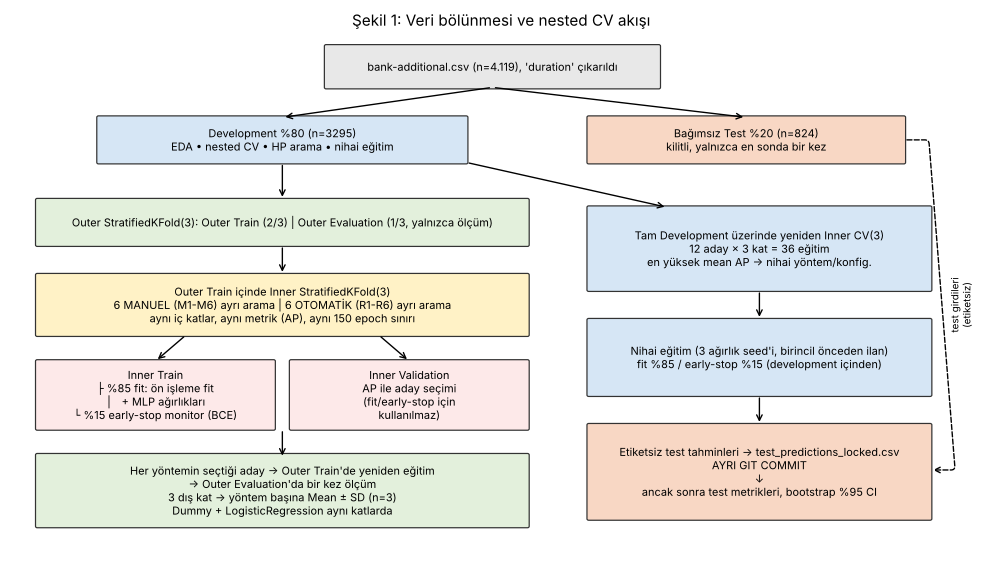

In [4]:
from matplotlib.patches import FancyBboxPatch
def box(ax, x, y, w, h, text, fc):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="#333", lw=.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=7.2)
def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", lw=.9))
fig, ax = plt.subplots(figsize=(11.5, 6.2)); ax.set_xlim(0, 11.2); ax.set_ylim(0, 7); ax.axis("off")
box(ax, 3.6, 6.3, 3.8, .55, f"bank-additional.csv (n=4.119), 'duration' çıkarıldı", "#e8e8e8")
box(ax, 1.0, 5.3, 4.2, .6, f"Development %80 (n={len(dev_idx)})\nEDA • nested CV • HP arama • nihai eğitim", "#d6e6f5")
box(ax, 6.6, 5.3, 3.6, .6, f"Bağımsız Test %20 (n={len(test_idx)})\nkilitli, yalnızca en sonda bir kez", "#f8d7c4")
arrow(ax, 5.5, 6.3, 3.1, 5.9); arrow(ax, 5.5, 6.3, 8.4, 5.9)
box(ax, 0.3, 4.2, 5.6, .6, "Outer StratifiedKFold(3): Outer Train (2/3) | Outer Evaluation (1/3, yalnızca ölçüm)", "#e3f0dc")
arrow(ax, 3.1, 5.3, 3.1, 4.8)
box(ax, 0.3, 3.0, 5.6, .8, "Outer Train içinde Inner StratifiedKFold(3)\n6 MANUEL (M1-M6) ayrı arama | 6 OTOMATİK (R1-R6) ayrı arama\naynı iç katlar, aynı metrik (AP), aynı 150 epoch sınırı", "#fff2c6")
arrow(ax, 3.1, 4.2, 3.1, 3.8)
box(ax, 0.3, 1.75, 2.7, .9, "Inner Train\n├ %85 fit: ön işleme fit\n│   + MLP ağırlıkları\n└ %15 early-stop monitor (BCE)", "#fde9e9")
box(ax, 3.2, 1.75, 2.7, .9, "Inner Validation\nAP ile aday seçimi\n(fit/early-stop için\nkullanılmaz)", "#fde9e9")
arrow(ax, 2.0, 3.0, 1.65, 2.65); arrow(ax, 4.2, 3.0, 4.55, 2.65)
box(ax, 0.3, 0.45, 5.6, .95, "Her yöntemin seçtiği aday → Outer Train'de yeniden eğitim\n→ Outer Evaluation'da bir kez ölçüm\n3 dış kat → yöntem başına Mean ± SD (n=3)\nDummy + LogisticRegression aynı katlarda", "#e3f0dc")
arrow(ax, 3.1, 1.75, 3.1, 1.35)
box(ax, 6.6, 3.6, 3.9, 1.1, "Tam Development üzerinde yeniden Inner CV(3)\n12 aday × 3 kat = 36 eğitim\nen yüksek mean AP → nihai yöntem/konfig.", "#d6e6f5")
box(ax, 6.6, 2.2, 3.9, 1.0, "Nihai eğitim (3 ağırlık seed'i, birincil önceden ilan)\nfit %85 / early-stop %15 (development içinden)", "#d6e6f5")
box(ax, 6.6, 0.55, 3.9, 1.25, "Etiketsiz test tahminleri → test_predictions_locked.csv\nAYRI GIT COMMIT\n↓\nancak sonra test metrikleri, bootstrap %95 CI", "#f8d7c4")
arrow(ax, 8.55, 3.6, 8.55, 3.2); arrow(ax, 8.55, 2.2, 8.55, 1.8); arrow(ax, 5.2, 5.3, 7.5, 4.7)
ax.annotate("", (10.5, 1.2), (10.2, 5.6), arrowprops=dict(arrowstyle="->", lw=.9, ls="--", connectionstyle="arc,angleA=0,angleB=0,armA=25,armB=25,rad=4"))
ax.text(10.85, 3.4, "test girdileri\n(etiketsiz)", rotation=90, ha="center", va="center", fontsize=6.5)
ax.set_title("Şekil 1: Veri bölünmesi ve nested CV akışı", fontsize=10)
fig.savefig(C.FIG_DIR / "fig01_nested_cv_flow.png"); plt.show()

## 3. Önceden sabitlenmiş adaylar (configs/, nested CV'den önce commit edildi)

In [5]:
cands = S.load_candidates()
# configs/ dosyalarının deterministik üreticiyle birebir aynı olduğunu doğrula
assert cands["manual"] == S.manual_candidates(), "manual_configs.json değişmiş!"
assert cands["random"] == S.random_candidates(), "random_configs.json değişmiş!"
# girdi boyutu: 9 sayısal + prev_contacted + one-hot kategori sayısı (fit gerektirmeyen sayım; parametre tablosu içindir)
N_IN = len(D.NUMERIC_COLS) + 1 + sum(X_dev[c].nunique() for c in D.CATEGORICAL_COLS)
tbl = []
for m in ("manual", "random"):
    for c in cands[m]:
        tbl.append({"code": c["code"], "purpose": c["purpose"], "optimizer": c["optimizer"], "hidden": tuple(c["hidden"]),
                    "activation": c["activation"], "lr": c["lr"], "weight_decay": c["weight_decay"], "batch_size": c["batch_size"],
                    "scaler": c["scaler"], "dropout": c["dropout"], "clipping": c["clipping"], "scheduler": c["scheduler"],
                    "n_params": count_params(N_IN, tuple(c["hidden"]))})
cand_tbl = pd.DataFrame(tbl); cand_tbl.to_csv(C.RESULTS_DIR / "candidate_table.csv", index=False)
print("MLP girdi boyutu (one-hot sonrası):", N_IN); display(cand_tbl)

MLP girdi boyutu (one-hot sonrası): 63


,code,purpose,optimizer,hidden,activation,lr,weight_decay,batch_size,scaler,dropout,clipping,scheduler,n_params
0,M1,Temel manuel konfigürasyon,adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2081
1,M2,Optimizer etkisi (AdamW -> Adam),adam,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2081
2,M3,Optimizer etkisi (AdamW -> SGD+Momentum 0.9),sgd,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,True,2081
3,M4,Ölçekleme etkisi (Standard -> MinMax),adamw,"(32,)",relu,0.001000,0.00010,64,minmax,0.0,False,True,2081
4,M5,"Mimari etkisi ((32,) -> (64,32))",adamw,"(64, 32)",relu,0.001000,0.00010,64,standard,0.0,False,True,6209
5,M6,Learning-rate-drop etkisi (scheduler kapalı),adamw,"(32,)",relu,0.001000,0.00010,64,standard,0.0,False,False,2081
6,R1,Random search (sgd),sgd,"(32,)",tanh,0.003726,0.00001,64,robust,0.0,False,True,2081
7,R2,Random search (sgd),sgd,"(32,)",relu,0.003363,0.00000,64,minmax,0.2,False,True,2081
8,R3,Random search (adam),adam,"(16,)",relu,0.008861,0.00010,32,robust,0.0,True,True,1041
9,R4,Random search (adam),adam,"(64, 32)",tanh,0.002154,0.00010,32,standard,0.0,True,True,6209


## 4. MLP mimari şeması ve öğrenilebilir parametre sayısı (Şekil 3)

In [6]:
def draw_arch(ax, n_in, hidden, act, title):
    dims = [n_in, *hidden, 1]; names = ["Girdi"] + [f"Gizli {i+1}\nLinear+{act}" for i in range(len(hidden))] + ["Çıkış\nLinear (1 logit)"]
    xs = np.linspace(.07, .74, len(dims))
    for i, (x, d, nm) in enumerate(zip(xs, dims, names)):
        h = .15 + .55 * np.log1p(d) / np.log1p(max(dims))
        ax.add_patch(FancyBboxPatch((x - .05, .5 - h / 2), .1, h, boxstyle="round,pad=0.01", fc="#d6e6f5" if 0 < i < len(dims) - 1 else "#eee", ec="#333"))
        ax.text(x, .5, f"{d}", ha="center", va="center", fontsize=9, weight="bold"); ax.text(x, .5 - h / 2 - .07, nm, ha="center", va="top", fontsize=7)
        if i:
            p = (dims[i - 1] + 1) * d
            ax.annotate("", (x - .05, .5), (xs[i - 1] + .05, .5), arrowprops=dict(arrowstyle="->"))
            ax.text((x + xs[i - 1]) / 2, .56, f"({dims[i-1]}+1)×{d}\n={p:,}", ha="center", fontsize=6.5)
    ax.text(.9, .5, "σ(·) → P(y=1)\neğitimde:\nBCEWithLogitsLoss", ha="center", va="center", fontsize=7)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off"); ax.set_title(f"{title}, toplam {count_params(n_in, tuple(hidden)):,} parametre", fontsize=8.5)
print("Parametre sayısı örnekleri:", {c: count_params(N_IN, h) for c, h in [("(32,)", (32,)), ("(64,32)", (64, 32)), ("(16,)", (16,)), ("(128,64)", (128, 64))]})
# Mimari şeması nihai model seçildikten sonra (Bölüm 7.2) çizilir.

Parametre sayısı örnekleri: {'(32,)': 2081, '(64,32)': 6209, '(16,)': 1041, '(128,64)': 16513}


## 5. Nested CV: 3 dış kat × 3 iç kat × (6 manuel + 6 otomatik) = 108 iç eğitim + 6 dış refit

In [7]:
C.set_global_seeds()
logs = []
t0 = time.perf_counter()
inner_long, inner_summ, outer_res, refit_logs = S.nested_cv(X_dev, y_dev, cands, log_sink=logs)
NESTED_TIME = time.perf_counter() - t0
print(f"Nested CV süresi: {NESTED_TIME/60:.1f} dk | iç eğitim sayısı: {len(inner_long)} | dış refit: {(outer_res.model.str.startswith('MLP')).sum()}")
pd.concat(logs, ignore_index=True).to_csv(C.LOG_DIR / "nested_inner_training_logs.csv", index=False)
refit_logs.to_csv(C.LOG_DIR / "nested_outer_refit_logs.csv", index=False)
outer_res.to_csv(C.RESULTS_DIR / "outer_cv_results.csv", index=False)

Nested CV süresi: 0.6 dk | iç eğitim sayısı: 108 | dış refit: 6


### 5.1 İç CV sonuçları (her dış kat içinde, aday başına mean AP ± SD, süre, en iyi epoch)

In [8]:
for m in ("manual", "random"):
    s = inner_summ.query("method==@m").copy(); mname = f"MLP-{m}"
    display(s.pivot(index="code", columns="stage", values="AP_mean").round(4).assign(
        selected_in=lambda t: [", ".join(outer_res.query("model==@mname and selected==@c")["outer_fold"].astype(str)) for c in t.index]))
    display(s[["stage", "code", "AP_mean", "AP_sd", "best_epoch_mean", "stopped_epoch_mean", "train_time_s_total", "n_params", "n_warnings"]].round(4))
w = inner_long[inner_long.warnings != ""]
print("Uyarılı iç eğitimler:", len(w)); display(w.groupby(["code", "warnings"]).size().rename("n").reset_index())

stage,outer1,outer2,outer3,selected_in
code,,,,
M1,0.4563,0.3965,0.3863,
M2,0.4574,0.3965,0.3845,"1, 2"
M3,0.4434,0.3812,0.3424,
M4,0.4506,0.3881,0.3935,3
M5,0.4398,0.3766,0.3747,
M6,0.4563,0.3965,0.3863,


,stage,code,AP_mean,AP_sd,best_epoch_mean,stopped_epoch_mean,train_time_s_total,n_params,n_warnings
0,outer1,M1,0.4563,0.0987,19.0000,34.0000,1.9260,2081,0
1,outer1,M2,0.4574,0.0999,19.0000,34.0000,0.6619,2081,0
2,outer1,M3,0.4434,0.0625,144.3333,150.0000,2.0798,2081,3
3,outer1,M4,0.4506,0.1015,20.3333,35.3333,0.6686,2081,0
4,outer1,M5,0.4398,0.0677,10.3333,25.3333,0.7948,6209,0
5,outer1,M6,0.4563,0.0987,19.0000,34.0000,0.6406,2081,0
12,outer2,M1,0.3965,0.0554,7.0000,22.0000,0.4133,2017,0
13,outer2,M2,0.3965,0.0562,7.0000,22.0000,0.4271,2017,0
14,outer2,M3,0.3812,0.0424,57.6667,72.6667,0.9559,2017,0
15,outer2,M4,0.3881,0.0252,10.6667,25.6667,0.4902,2017,0


stage,outer1,outer2,outer3,selected_in
code,,,,
R1,0.4493,0.3940,0.3557,
R2,0.4584,0.3665,0.3797,
R3,0.4270,0.3942,0.3670,2
R4,0.4568,0.3774,0.4004,3
R5,0.4665,0.3930,0.3794,1
R6,0.4605,0.3928,0.3868,


,stage,code,AP_mean,AP_sd,best_epoch_mean,stopped_epoch_mean,train_time_s_total,n_params,n_warnings
6,outer1,R1,0.4493,0.0934,58.0000,73.0000,1.1778,2081,0
7,outer1,R2,0.4584,0.1030,89.3333,104.3333,1.7796,2081,0
8,outer1,R3,0.4270,0.0791,4.3333,19.3333,0.6907,1041,0
9,outer1,R4,0.4568,0.1182,5.3333,20.3333,0.9529,6209,1
10,outer1,R5,0.4665,0.1030,36.3333,51.3333,1.8531,1041,0
11,outer1,R6,0.4605,0.0928,7.6667,22.6667,0.4392,16513,0
18,outer2,R1,0.3940,0.0591,23.6667,38.6667,0.5173,2017,0
19,outer2,R2,0.3665,0.0387,31.3333,46.3333,0.7110,2017,0
20,outer2,R3,0.3942,0.0526,2.6667,17.6667,0.6004,1009,1
21,outer2,R4,0.3774,0.0647,2.6667,17.6667,0.8336,6081,2


Uyarılı iç eğitimler: 12


,code,warnings,n
0,M3,max_epochs reached without early stop (possibl...,4
1,M5,best epoch very early (2),1
2,R3,best epoch very early (2),3
3,R4,best epoch very early (1),2
4,R4,best epoch very early (2),2


### 5.2 Dış kat (outer evaluation) sonuçları, kat bazlı ham tablo ve Mean ± SD (n=3)

In [9]:
cols = ["outer_fold", "model", "selected", "inner_AP_mean"] + METRIC_ORDER + ["PR_AUC_trapezoid", "fit_time_s", "TP", "FP", "TN", "FN"]
display(outer_res[cols].round(4))
ms = mean_sd(outer_res, "model", METRIC_ORDER + ["fit_time_s"])
ms = ms.loc[["MLP-manual", "MLP-random", "LogisticRegression", "Dummy(prior)"]]
ms.to_csv(C.RESULTS_DIR / "outer_cv_mean_sd.csv"); display(ms)

,outer_fold,model,selected,inner_AP_mean,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,PR_AUC_trapezoid,fit_time_s,TP,FP,TN,FN
0,1,MLP-manual,M2,0.4574,0.3514,0.7279,0.8926,0.5385,0.1736,0.9816,0.2625,0.5776,0.3483,0.2635,21,18,960,100
1,1,MLP-random,R5,0.4665,0.3547,0.7165,0.8954,0.5938,0.1570,0.9867,0.2484,0.5719,0.3522,0.5913,19,13,965,102
2,1,LogisticRegression,-,NaN,0.3491,0.7159,0.8917,0.5208,0.2066,0.9765,0.2959,0.5915,0.3453,0.0335,25,23,955,96
3,1,Dummy(prior),-,NaN,0.1101,0.5000,0.8899,0.0000,0.0000,1.0000,0.0000,0.5000,0.5551,0.0004,0,0,978,121
4,2,MLP-manual,M2,0.3965,0.4604,0.8045,0.9007,0.6170,0.2417,0.9816,0.3473,0.6116,0.4575,0.2616,29,18,960,91
5,2,MLP-random,R3,0.3942,0.4339,0.7927,0.9016,0.6304,0.2417,0.9826,0.3494,0.6121,0.4547,0.3649,29,17,961,91
6,2,LogisticRegression,-,NaN,0.4703,0.7935,0.8989,0.5789,0.2750,0.9755,0.3729,0.6252,0.4675,0.0296,33,24,954,87
7,2,Dummy(prior),-,NaN,0.1093,0.5000,0.8907,0.0000,0.0000,1.0000,0.0000,0.5000,0.5546,0.0003,0,0,978,120
8,3,MLP-manual,M4,0.3935,0.4536,0.7704,0.8998,0.8125,0.1083,0.9969,0.1912,0.5526,0.4515,0.2393,13,3,975,107
9,3,MLP-random,R4,0.4004,0.4263,0.7706,0.8989,0.6552,0.1583,0.9898,0.2550,0.5741,0.4232,0.4092,19,10,968,101


,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,fit_time_s
model,,,,,,,,,
MLP-manual,0.4218 ± 0.0611,0.7676 ± 0.0384,0.8977 ± 0.0044,0.6560 ± 0.1411,0.1745 ± 0.0667,0.9867 ± 0.0089,0.2670 ± 0.0782,0.5806 ± 0.0296,0.2548 ± 0.0135
MLP-random,0.4050 ± 0.0437,0.7599 ± 0.0392,0.8986 ± 0.0031,0.6265 ± 0.0309,0.1857 ± 0.0485,0.9864 ± 0.0036,0.2843 ± 0.0565,0.5860 ± 0.0226,0.4551 ± 0.1200
LogisticRegression,0.4142 ± 0.0611,0.7552 ± 0.0388,0.8974 ± 0.0051,0.5888 ± 0.0734,0.2272 ± 0.0415,0.9799 ± 0.0068,0.3255 ± 0.0415,0.6035 ± 0.0188,0.0308 ± 0.0024
Dummy(prior),0.1096 ± 0.0005,0.5000 ± 0.0000,0.8904 ± 0.0005,0.0000 ± 0.0000,0.0000 ± 0.0000,1.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.0003 ± 0.0000


**Not:** Üç dış kat bağımsız tekrarlar değildir (eğitim kümeleri örtüşür); SD bir güven aralığı gibi yorumlanamaz ve n=3
belirsizliği sınırlı temsil eder. Dış kat skorları, arama **prosedürlerinin** genelleme performansını tanımlar; manuel
konfigürasyonları değiştirmek veya nihai yöntemi seçmek için kullanılmaz.

## 6. Tam development üzerinde yeniden iç CV → nihai seçim (12 aday × 3 kat = 36 eğitim)

In [10]:
C.set_global_seeds()
final_logs = []
fl_long, fl_summ = [], []
for m in ("manual", "random"):
    L, Sm = S.inner_cv(X_dev, y_dev, cands[m], "full_dev", m, log_sink=final_logs)
    fl_long.append(L); fl_summ.append(Sm)
fl_long, fl_summ = pd.concat(fl_long, ignore_index=True), pd.concat(fl_summ, ignore_index=True)
pd.concat(final_logs, ignore_index=True).to_csv(C.LOG_DIR / "full_dev_inner_training_logs.csv", index=False)

# arama sonuç dosyaları: tüm aşamalar (outer1..3 + full_dev), kat bazlı ve özet
all_long = pd.concat([inner_long, fl_long], ignore_index=True); all_summ = pd.concat([inner_summ, fl_summ], ignore_index=True)
for m, fn in (("manual", "manual_search_results"), ("random", "random_search_results")):
    all_summ.query("method==@m").to_csv(C.RESULTS_DIR / f"{fn}.csv", index=False)
    all_long.query("method==@m").to_csv(C.RESULTS_DIR / f"{fn}_per_fold.csv", index=False)

best = {m: S.select_best(fl_summ.query("method==@m")) for m in ("manual", "random")}
best_ap = {m: float(fl_summ.set_index("code").loc[best[m], "AP_mean"]) for m in best}
FINAL_METHOD = max(best_ap, key=best_ap.get)
FINAL_CODE = best[FINAL_METHOD]
final_cfg = next(c for c in cands[FINAL_METHOD] if c["code"] == FINAL_CODE)
display(fl_summ[["method", "code", "AP_mean", "AP_sd", "best_epoch_mean", "train_time_s_total", "n_params", "config"]].round(4))
print("Yöntem başına seçilen:", best, best_ap)
print(f"NİHAİ: yöntem={FINAL_METHOD}, aday={FINAL_CODE} -> {S.cfg_short(final_cfg)}")

,method,code,AP_mean,AP_sd,best_epoch_mean,train_time_s_total,n_params,config
0,manual,M1,0.4232,0.0260,12.6667,0.7897,2049,"adamw|(32,)|relu|lr=1.00e-03|wd=0.0001|bs=64|s..."
1,manual,M2,0.4235,0.0263,12.6667,0.7830,2049,"adam|(32,)|relu|lr=1.00e-03|wd=0.0001|bs=64|st..."
2,manual,M3,0.4172,0.0117,125.3333,2.6266,2049,"sgd|(32,)|relu|lr=1.00e-03|wd=0.0001|bs=64|sta..."
3,manual,M4,0.4176,0.0250,24.0000,1.0886,2049,"adamw|(32,)|relu|lr=1.00e-03|wd=0.0001|bs=64|m..."
4,manual,M5,0.4281,0.0130,7.0000,0.8630,6145,"adamw|(64, 32)|relu|lr=1.00e-03|wd=0.0001|bs=6..."
5,manual,M6,0.4232,0.0260,12.6667,0.7727,2049,"adamw|(32,)|relu|lr=1.00e-03|wd=0.0001|bs=64|s..."
6,random,R1,0.4320,0.0206,54.0000,1.3432,2049,"sgd|(32,)|tanh|lr=3.73e-03|wd=1e-05|bs=64|robu..."
7,random,R2,0.4190,0.0188,83.6667,2.2648,2049,"sgd|(32,)|relu|lr=3.36e-03|wd=0|bs=64|minmax|d..."
8,random,R3,0.4015,0.0290,5.3333,1.0670,1025,"adam|(16,)|relu|lr=8.86e-03|wd=0.0001|bs=32|ro..."
9,random,R4,0.4229,0.0346,4.6667,1.4596,6145,"adam|(64, 32)|tanh|lr=2.15e-03|wd=0.0001|bs=32..."


Yöntem başına seçilen: {'manual': 'M5', 'random': 'R5'} {'manual': 0.4280902384415173, 'random': 0.43704498600018543}
NİHAİ: yöntem=random, aday=R5 -> adamw|(16,)|tanh|lr=3.71e-04|wd=0|bs=32|standard|do=0.2|clip=False|sched=True


### 6.1 Manuel ve otomatik arama sonuçlarının karşılaştırmalı grafiği (Şekil 5)

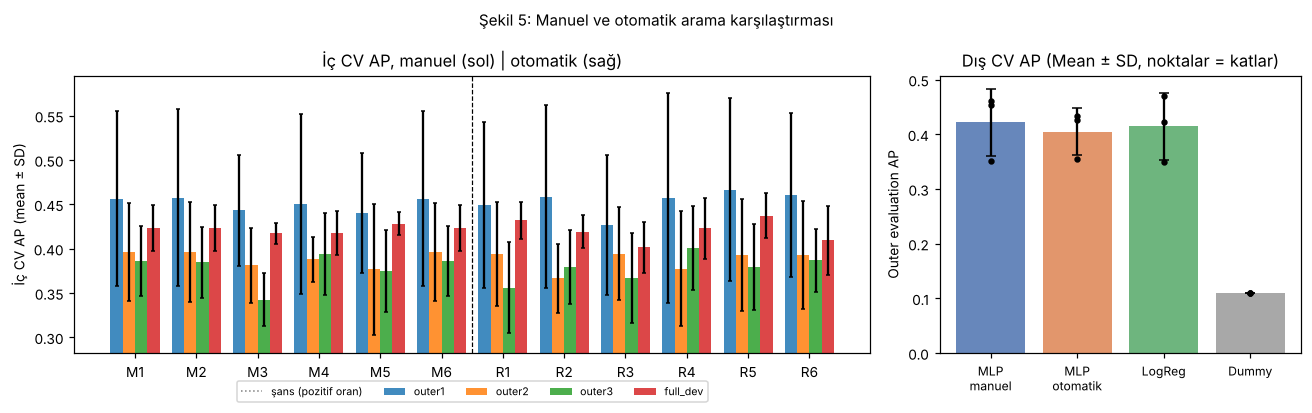

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]; stages = ["outer1", "outer2", "outer3", "full_dev"]; codes = [c["code"] for c in cands["manual"] + cands["random"]]
x = np.arange(len(codes)); wdt = .2
for i, st in enumerate(stages):
    s = all_summ.query("stage==@st").set_index("code").loc[codes]
    ax.bar(x + (i - 1.5) * wdt, s["AP_mean"], wdt, yerr=s["AP_sd"], capsize=1.5, label=st, alpha=.85)
ax.axvline(5.5, color="k", lw=.8, ls="--"); ax.set_xticks(x); ax.set_xticklabels(codes)
ax.set_ylabel("İç CV AP (mean ± SD)"); ax.axhline(y_dev.mean(), color="gray", ls=":", lw=1, label="şans (pozitif oran)")
ax.set_ylim(max(0, (all_summ.AP_mean - all_summ.AP_sd).min() - .02), (all_summ.AP_mean + all_summ.AP_sd).max() + .02)
ax.legend(fontsize=7, ncol=5, loc="upper center", bbox_to_anchor=(.5, -.08)); ax.set_title("İç CV AP, manuel (sol) | otomatik (sağ)")
ax = axes[1]
order = ["MLP-manual", "MLP-random", "LogisticRegression", "Dummy(prior)"]
for j, mdl in enumerate(order):
    v = outer_res.query("model==@mdl")["AP"].to_numpy()
    ax.bar(j, v.mean(), yerr=v.std(ddof=1), capsize=3, color=["#4c72b0", "#dd8452", "#55a868", "#999"][j], alpha=.85)
    ax.scatter(np.full(3, j), v, color="k", s=10, zorder=3)
ax.set_xticks(range(4)); ax.set_xticklabels(["MLP\nmanuel", "MLP\notomatik", "LogReg", "Dummy"], fontsize=8)
ax.set_ylabel("Outer evaluation AP"); ax.set_title("Dış CV AP (Mean ± SD, noktalar = katlar)")
fig.suptitle("Şekil 5: Manuel ve otomatik arama karşılaştırması", fontsize=10); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig05_manual_vs_random.png"); plt.show()

### 6.2 Ek duyarlılık deneyi (ana 6+6 bütçenin dışında): `unknown` = ayrı kategori vs kat-içi en sık sınıf
Yalnızca development iç CV'si ile, nihai konfigürasyon sabit tutularak yapılır. Nihai kararı **değiştirmez**
(önceden belirlenmiş kural: `unknown` ayrı kategori). Sonucu raporda alternatif olarak verdim.

In [12]:
alt = {**final_cfg, "code": FINAL_CODE + "-unkMF", "unknown": "most_frequent"}
L_alt, S_alt = S.inner_cv(X_dev, y_dev, [alt], "full_dev_sensitivity", "extra")
unk_cmp = pd.concat([fl_summ.query("code==@FINAL_CODE"), S_alt])[["code", "AP_mean", "AP_sd", "best_epoch_mean"]]
unk_cmp.to_csv(C.RESULTS_DIR / "extra_unknown_sensitivity.csv", index=False); display(unk_cmp.round(4))

,code,AP_mean,AP_sd,best_epoch_mean
10,R5,0.437,0.0256,32.0
0,R5-unkMF,0.439,0.0161,32.0


## 7. Nihai model eğitimi: 3 önceden ilan edilmiş ağırlık seed'i (birincil = ilk seed)

In [13]:
final_models, final_hist = {}, []
for s in C.FINAL_TORCH_SEEDS:
    m = MLPPipeline(final_cfg, torch_seed=s).fit(X_dev, y_dev)
    final_models[s] = m
    h = m.result_.history.copy(); h.insert(0, "torch_seed", s); final_hist.append(h)
    joblib.dump(m.pre_, C.MODEL_DIR / f"preprocessor_seed{s}.joblib")
    torch.save(m.result_.model.state_dict(), C.MODEL_DIR / f"mlp_seed{s}.pt")
    print(f"seed={s}: best_epoch={m.result_.best_epoch}, stopped={m.result_.stopped_epoch}, "
          f"time={m.result_.train_time_s:.1f}s, uyarı={m.result_.warnings}")
final_hist = pd.concat(final_hist, ignore_index=True); final_hist.to_csv(C.LOG_DIR / "final_model_training_logs.csv", index=False)

lr_final, lr_time, lr_warn = S.fit_reference(S.make_logreg(), X_dev, y_dev)
dummy_final, _, _ = S.fit_reference(S.make_dummy(), X_dev, y_dev)
joblib.dump(lr_final, C.MODEL_DIR / "logreg_final.joblib")

pm = final_models[C.PRIMARY_TORCH_SEED]
final_json = {
    "selected_method": FINAL_METHOD, "selected_code": FINAL_CODE, "config": final_cfg,
    "selection_evidence": {"full_dev_inner_AP": best_ap, "per_method_best": best},
    "primary_torch_seed": C.PRIMARY_TORCH_SEED, "all_torch_seeds": C.FINAL_TORCH_SEEDS,
    "early_stop_split_seed": C.SEEDS["early_stop_split"], "threshold": C.THRESHOLD,
    "n_input_features": int(pm.pre_.transform(X_dev.iloc[:1]).shape[1]), "n_params": pm.result_.n_params,
    "per_seed": {str(s): {"best_epoch": m.result_.best_epoch, "stopped_epoch": m.result_.stopped_epoch,
                          "train_time_s": m.result_.train_time_s, "warnings": m.result_.warnings,
                          "n_fit": m.n_fit_, "n_monitor": m.n_monitor_} for s, m in final_models.items()},
    "learned_preprocessing_primary_seed": fitted_state(pm.pre_),
    "logreg_reference": {"preprocessing": "standard, no clipping, unknown=category", "C": 1.0, "fit_time_s": lr_time, "warnings": lr_warn},
    "nested_cv_time_s": NESTED_TIME,
}
json.dump(final_json, open(C.RESULTS_DIR / "final_hyperparameters.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps({k: v for k, v in final_json.items() if k != "learned_preprocessing_primary_seed"}, indent=1, ensure_ascii=False)[:1500])

seed=31068: best_epoch=20, stopped=35, time=1.0s, uyarı=[]


seed=31166: best_epoch=23, stopped=38, time=1.0s, uyarı=[]


seed=31266: best_epoch=19, stopped=34, time=0.9s, uyarı=[]
{
 "selected_method": "random",
 "selected_code": "R5",
 "config": {
  "code": "R5",
  "purpose": "Random search (adamw)",
  "optimizer": "adamw",
  "scheduler": true,
  "unknown": "category",
  "activation": "tanh",
  "batch_size": 32,
  "clipping": false,
  "dropout": 0.2,
  "hidden": [
   16
  ],
  "lr": 0.0003711806663886465,
  "scaler": "standard",
  "weight_decay": 0.0
 },
 "selection_evidence": {
  "full_dev_inner_AP": {
   "manual": 0.4280902384415173,
   "random": 0.43704498600018543
  },
  "per_method_best": {
   "manual": "M5",
   "random": "R5"
  }
 },
 "primary_torch_seed": 31068,
 "all_torch_seeds": [
  31068,
  31166,
  31266
 ],
 "early_stop_split_seed": 31073,
 "threshold": 0.5,
 "n_input_features": 62,
 "n_params": 1025,
 "per_seed": {
  "31068": {
   "best_epoch": 20,
   "stopped_epoch": 35,
   "train_time_s": 1.0072683710000092,
   "warnings": [],
   "n_fit": 2800,
   "n_monitor": 495
  },
  "31166": {
   "b

### 7.1 Eğitim ve iç early-stop doğrulama kaybı, epoch bazlı öğrenme oranı (Şekil 4)

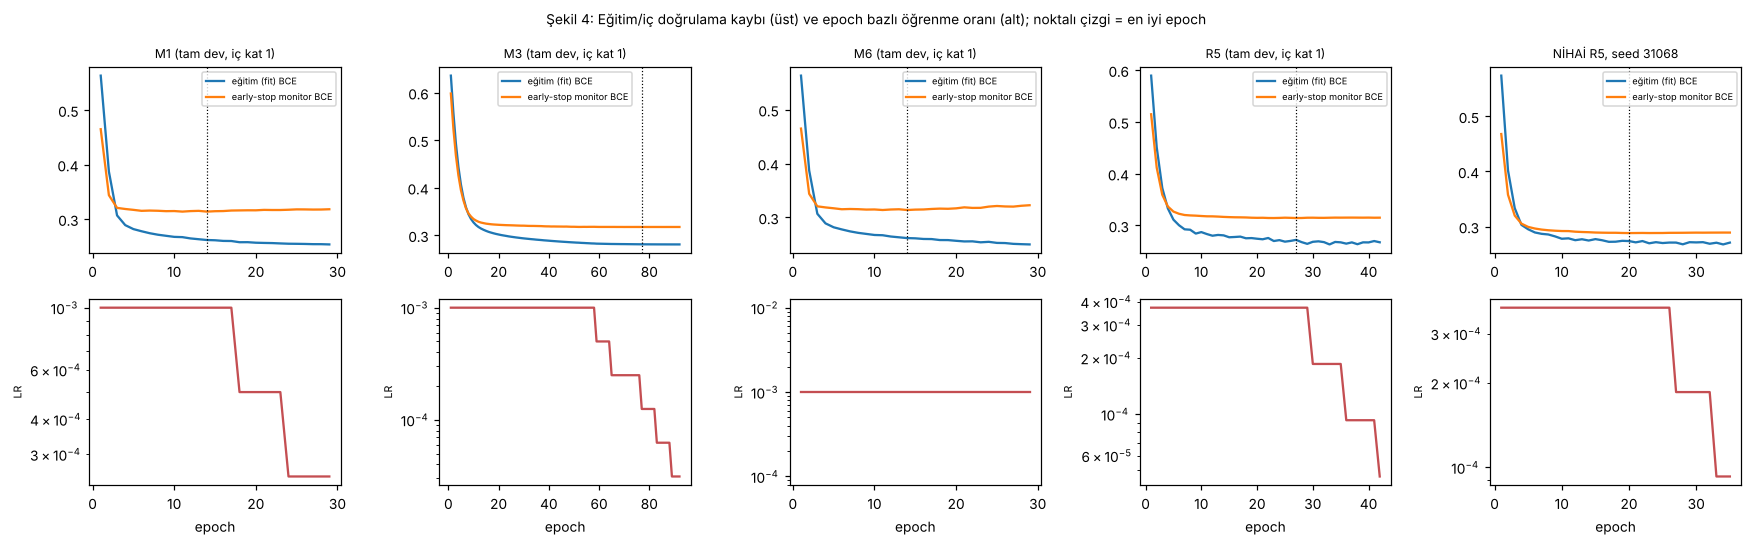

In [14]:
fl_logs = pd.concat(final_logs, ignore_index=True)
show = [c for c in ["M1", "M3", "M6", FINAL_CODE] if c in fl_logs.code.unique()]
show = list(dict.fromkeys(show))
fig, axes = plt.subplots(2, len(show) + 1, figsize=(3.2 * (len(show) + 1), 5), sharex=False)
def plot_hist(axl, axr, h, title, best_ep):
    axl.plot(h.epoch, h.train_loss, label="eğitim (fit) BCE"); axl.plot(h.epoch, h.val_loss, label="early-stop monitor BCE")
    axl.axvline(best_ep, color="k", ls=":", lw=.8); axl.set_title(title, fontsize=8); axl.legend(fontsize=6)
    axr.plot(h.epoch, h.lr, color="#c44e52"); axr.set_yscale("log"); axr.set_xlabel("epoch"); axr.set_ylabel("LR", fontsize=7)
for j, code in enumerate(show):
    h = fl_logs.query("code==@code and inner_fold==1")
    b = int(fl_long.query("code==@code and inner_fold==1")["best_epoch"].iloc[0])
    plot_hist(axes[0, j], axes[1, j], h, f"{code} (tam dev, iç kat 1)", b)
h = final_hist.query("torch_seed==@C.PRIMARY_TORCH_SEED")
plot_hist(axes[0, -1], axes[1, -1], h, f"NİHAİ {FINAL_CODE}, seed {C.PRIMARY_TORCH_SEED}", pm.result_.best_epoch)
fig.suptitle("Şekil 4: Eğitim/iç doğrulama kaybı (üst) ve epoch bazlı öğrenme oranı (alt); noktalı çizgi = en iyi epoch", fontsize=9)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "fig04_loss_lr_curves.png"); plt.show()

### 7.2 MLP mimari şeması ve öğrenilebilir parametre sayısı (Şekil 3)

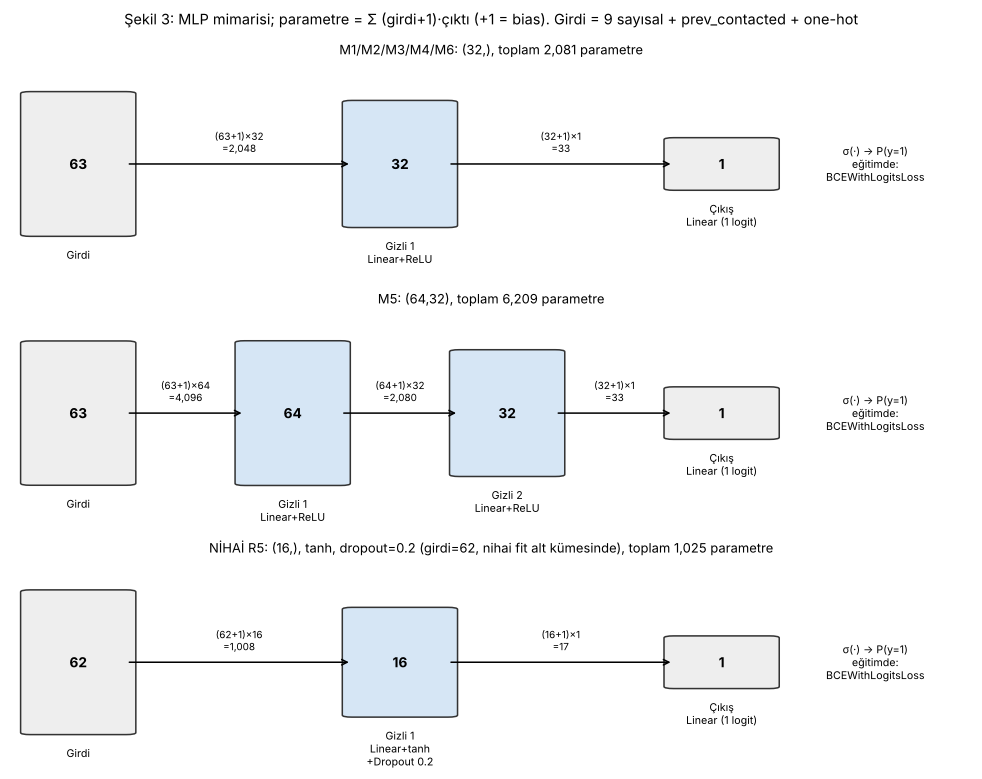

In [15]:
n_final = final_json["n_input_features"]; act_name = {"relu": "ReLU", "tanh": "tanh"}[final_cfg["activation"]]
fig, axes = plt.subplots(3, 1, figsize=(9, 7.2))
draw_arch(axes[0], N_IN, (32,), "ReLU", "M1/M2/M3/M4/M6: (32,)"); draw_arch(axes[1], N_IN, (64, 32), "ReLU", "M5: (64,32)")
draw_arch(axes[2], n_final, tuple(final_cfg["hidden"]), act_name + (f"\n+Dropout {final_cfg['dropout']}" if final_cfg["dropout"] else ""),
          f"NİHAİ {FINAL_CODE}: {tuple(final_cfg['hidden'])}, {act_name}, dropout={final_cfg['dropout']} (girdi={n_final}, nihai fit alt kümesinde)")
fig.suptitle("Şekil 3: MLP mimarisi; parametre = Σ (girdi+1)·çıktı (+1 = bias). Girdi = 9 sayısal + prev_contacted + one-hot", fontsize=9.5)
fig.tight_layout(); fig.savefig(C.FIG_DIR / "fig03_mlp_architecture.png"); plt.show()

## 8. Test tahminlerinin kilitlenmesi
Test kümesinden **yalnızca girdi sütunları** okunur (`y` sütunu düşürülür). Üç MLP seed'i ve LogisticRegression/Dummy
referanslarının olasılıkları ile 0.50 eşiğindeki sınıf tahminleri `test_predictions_locked.csv` dosyasına yazılır.
Bu dosya ve `final_hyperparameters.json` **ayrı bir git commit** ile repoya gönderildikten sonra 03 notebook'u çalıştırılır.

In [16]:
X_test = df.iloc[test_idx].drop(columns=["y"] + D.DROP_COLS).reset_index(drop=True)   # etiket yok
assert "y" not in X_test.columns
locked = pd.DataFrame({"original_row_index": test_idx})
for s, m in final_models.items():
    p = m.predict_proba(X_test)
    locked[f"mlp_proba_seed{s}"] = p; locked[f"mlp_pred_seed{s}"] = (p >= C.THRESHOLD).astype(int)
locked["logreg_proba"] = lr_final.predict_proba(X_test)[:, 1]; locked["logreg_pred"] = (locked["logreg_proba"] >= C.THRESHOLD).astype(int)
locked["dummy_proba"] = dummy_final.predict_proba(X_test)[:, 1]; locked["dummy_pred"] = (locked["dummy_proba"] >= C.THRESHOLD).astype(int)
locked.to_csv(C.RESULTS_DIR / "test_predictions_locked.csv", index=False)
json.dump({"primary_model": f"mlp_proba_seed{C.PRIMARY_TORCH_SEED}", "primary_seed": C.PRIMARY_TORCH_SEED,
           "final_code": FINAL_CODE, "threshold": C.THRESHOLD, "n_test": len(locked),
           "note": "Etiket içermez. Bu dosya ayrı commit ile kilitlendikten sonra test metrikleri hesaplanır."},
          open(C.RESULTS_DIR / "test_predictions_locked_manifest.json", "w"), indent=2)
print(locked.shape, list(locked.columns)); display(locked.head())

(824, 11) ['original_row_index', 'mlp_proba_seed31068', 'mlp_pred_seed31068', 'mlp_proba_seed31166', 'mlp_pred_seed31166', 'mlp_proba_seed31266', 'mlp_pred_seed31266', 'logreg_proba', 'logreg_pred', 'dummy_proba', 'dummy_pred']


,original_row_index,mlp_proba_seed31068,mlp_pred_seed31068,mlp_proba_seed31166,mlp_pred_seed31166,mlp_proba_seed31266,mlp_pred_seed31266,logreg_proba,logreg_pred,dummy_proba,dummy_pred
0,12,0.047598,0,0.045307,0,0.047489,0,0.047788,0,0.10956,0
1,14,0.117512,0,0.115870,0,0.112375,0,0.096655,0,0.10956,0
2,16,0.052117,0,0.046382,0,0.047072,0,0.062876,0,0.10956,0
3,20,0.042119,0,0.040254,0,0.044859,0,0.058203,0,0.10956,0
4,31,0.042987,0,0.044281,0,0.048925,0,0.053535,0,0.10956,0
